# R1_D - Synergy-constrained animal-held-out test
The analysis tests whether awake synergy-selected n-plets discriminate held-out scans and whether adding Omega improves the matched-region pairwise vector. Performance is reported with ROC-AUC and PR-AUC; raw Omega remains a separate synergy-direction diagnostic. Pooled scores mix fold-specific models, so interpret them with the scale caveat below.

In [28]:
from pathlib import Path
import os
import sys

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src' / 'hoi_anesthesia').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook inside the repository.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score
from src.hoi_anesthesia.io import load_covariance_dict
from src.hoi_anesthesia.validation import (
    LOAOCheckpointStore, SearchSettings, animal_balanced_weights, build_synergy_manifest,
    configure_loao_logger, evaluate_synergy_models, load_classification_data,
    loao_run_id, run_synergy_selection_stage,
    save_synergy_result,
)
from src.hoi_anesthesia.plotting import plot_synergy_pairwise_silence

## Settings
The checkpoint manifest fingerprints inputs, folds, search settings, and the R1_D admissibility rule.

In [29]:
SETTINGS = SearchSettings(
    restarts=100, iterations=20000, early_stop=1000,
    temperature=0.05, cooling=0.99, batch_size=14000, seed=2026,
)
EXHAUSTIVE_ORDERS = (3, 4, 5)
ANNEALING_ORDERS = (6, 7, 8, 9)
ALL_ORDERS = EXHAUSTIVE_ORDERS + ANNEALING_ORDERS
DATASETS = ('MA', 'DBS')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
NEAR_CHANCE_ROC_AUC_THRESHOLD = 0.55
COVARIANCE_PATH = ROOT / 'data' / 'covariance_matrices_gc.h5'
METADATA_PATH = ROOT / 'data' / 'scan_metadata.csv'
OUTPUT = ROOT / 'results' / 'R1_D_synergy'
RUN_MANIFEST = build_synergy_manifest(
    COVARIANCE_PATH, METADATA_PATH, SETTINGS, DATASETS, DEVICE,
)
RUN_ID = loao_run_id(RUN_MANIFEST)
CHECKPOINT_DIR = OUTPUT / 'checkpoints' / RUN_ID
CHECKPOINTS = LOAOCheckpointStore(CHECKPOINT_DIR, RUN_MANIFEST)
LOGGER = configure_loao_logger(CHECKPOINT_DIR / 'run.log')
LOGGER.info('R1_D run_id=%s device=%s datasets=%s', RUN_ID, DEVICE, DATASETS)
LOGGER.info('Run manifest: %s', RUN_MANIFEST)

2026-11-05 01:06:10,670 INFO R1_D run_id=aca64fac449d53736c22 device=cuda datasets=('MA', 'DBS')
2026-11-05 01:06:10,670 INFO Run manifest: {'checkpoint_schema': 1, 'algorithm_version': 1, 'inputs': {'covariance_sha256': 'b72d47513317a87f8778f0076775ca31f3bb5dd7e602f385bf3ec6bd2ff6be09', 'metadata_sha256': '3346544edbb3d1500e4d87451c642eea5c1766de0e7166b2b432ce4935091e96'}, 'settings': {'restarts': 100, 'iterations': 20000, 'early_stop': 1000, 'temperature': 0.05, 'cooling': 0.99, 'batch_size': 14000, 'seed': 2026}, 'datasets': ['MA', 'DBS'], 'device': 'cuda', 'orders': {'exhaustive': [3, 4, 5], 'annealing': [6, 7, 8, 9]}, 'analysis': 'R1_D_synergy_loao', 'selection_rule': {'measure': 'raw_omega', 'polarity': -1, 'training_responsive_weighted_median_below': 0, 'tie_break': ['most_negative_training_responsive_median', 'lexicographic_nplet'], 'pairwise_reference': 'best_of_both_mean_fc_auc_directions'}, 'criterion_3_near_chance_balanced_accuracy': 0.55}


## Inputs
Classification scans and labels use the same metadata alignment as R1_A.

In [30]:
metadata = pd.read_csv(METADATA_PATH, dtype={'animal': str, 'session': str, 'run': str})
all_covariances = load_covariance_dict(COVARIANCE_PATH)
inputs = {
    dataset: load_classification_data(all_covariances, metadata, dataset)
    for dataset in DATASETS
}
display(pd.concat([
    scans.groupby(['dataset', 'animal', 'state']).agg(
        scans=('scan_index', 'size'), sessions=('session', 'nunique'),
    )
    for _, scans in inputs.values()
]))

scans  sessions
dataset animal state                            
MA      A      MA_awake              2         1
        J      MA_awake             14         7
               deep_propofol         4         3
        K      MA_awake              8         8
               deep_propofol         8         5
               ketamine              8         4
        L      ketamine              6         4
               ts_selv4              2         2
        R      deep_propofol        11         6
               ketamine              8         6
               ts_selv4              9         4
DBS     B      DBS_awake            14         1
        J      DBS_awake             7         2
        N      ts_off               10         2
        T      ts_off               18         6
               ts_on_3V_control     18         2
               ts_on_5V_control     18         2
        Y      DBS_awake            15         3

## Omega selection: orders 3-5
Each order traverses candidates once and retains an independent best n-plet for every pending fold. Fold-specific training AUC of -Omega is maximized only among n-plets with a negative weighted awake median.

In [31]:
omega_exhaustive = {}
for dataset, (covariances, scans) in inputs.items():
    omega_exhaustive[dataset] = run_synergy_selection_stage(
        covariances, scans, EXHAUSTIVE_ORDERS,
        strategy='synergy_exhaustive', settings=SETTINGS, device=DEVICE,
        checkpoint=CHECKPOINTS, logger=LOGGER,
    )
omega_exhaustive_selections = pd.concat(omega_exhaustive.values(), ignore_index=True)
print('Exhaustive synergy-constrained selections (orders 3-5)')
display(omega_exhaustive_selections.sort_values(
    ['dataset', 'order', 'held_out_animal'],
)[['dataset', 'order', 'held_out_animal', 'nplet', 'training_auc',
   'train_median_R', 'train_median_NR', 'n_admissible', 'n_tied']])

2026-11-05 01:06:10,781 INFO Starting strategy=synergy_exhaustive dataset=MA held_out_animal=A n=3
2026-11-05 01:06:10,781 INFO Reused checkpoint for strategy=synergy_exhaustive dataset=MA held_out_animal=A n=3
2026-11-05 01:06:10,782 INFO Starting strategy=synergy_exhaustive dataset=MA held_out_animal=J n=3
2026-11-05 01:06:10,782 INFO Reused checkpoint for strategy=synergy_exhaustive dataset=MA held_out_animal=J n=3
2026-11-05 01:06:10,782 INFO Starting strategy=synergy_exhaustive dataset=MA held_out_animal=K n=3
2026-11-05 01:06:10,783 INFO Reused checkpoint for strategy=synergy_exhaustive dataset=MA held_out_animal=K n=3
2026-11-05 01:06:10,783 INFO Starting strategy=synergy_exhaustive dataset=MA held_out_animal=L n=3
2026-11-05 01:06:10,784 INFO Reused checkpoint for strategy=synergy_exhaustive dataset=MA held_out_animal=L n=3
2026-11-05 01:06:10,784 INFO Starting strategy=synergy_exhaustive dataset=MA held_out_animal=R n=3
2026-11-05 01:06:10,784 INFO Reused checkpoint for strate

## Omega selection: orders 6-9
Annealing penalizes inadmissible candidates and chooses among admissible restart endpoints only.

In [32]:
omega_annealing = {}
for dataset, (covariances, scans) in inputs.items():
    omega_annealing[dataset] = run_synergy_selection_stage(
        covariances, scans, ANNEALING_ORDERS,
        strategy='synergy_annealing', settings=SETTINGS, device=DEVICE,
        checkpoint=CHECKPOINTS, logger=LOGGER,
    )
omega_annealing_selections = pd.concat(omega_annealing.values(), ignore_index=True)
print('Simulated-annealing synergy-constrained selections (orders 6-9)')
display(omega_annealing_selections.sort_values(
    ['dataset', 'order', 'held_out_animal'],
)[['dataset', 'order', 'held_out_animal', 'nplet', 'training_auc',
   'train_median_R', 'train_median_NR', 'admissible_restarts', 'n_tied']])

2026-11-05 01:06:10,806 INFO Starting strategy=synergy_annealing dataset=MA held_out_animal=A n=6
2026-11-05 01:06:10,807 INFO Reused checkpoint for strategy=synergy_annealing dataset=MA held_out_animal=A n=6
2026-11-05 01:06:10,807 INFO Starting strategy=synergy_annealing dataset=MA held_out_animal=A n=7
2026-11-05 01:06:10,807 INFO Reused checkpoint for strategy=synergy_annealing dataset=MA held_out_animal=A n=7
2026-11-05 01:06:10,808 INFO Starting strategy=synergy_annealing dataset=MA held_out_animal=A n=8
2026-11-05 01:06:10,808 INFO Reused checkpoint for strategy=synergy_annealing dataset=MA held_out_animal=A n=8
2026-11-05 01:06:10,809 INFO Starting strategy=synergy_annealing dataset=MA held_out_animal=A n=9
2026-11-05 01:06:10,809 INFO Reused checkpoint for strategy=synergy_annealing dataset=MA held_out_animal=A n=9
2026-11-05 01:06:10,810 INFO Starting strategy=synergy_annealing dataset=MA held_out_animal=J n=6
2026-11-05 01:06:10,810 INFO Reused checkpoint for strategy=synerg

## Best pairwise reference: orders 3-9
This exploratory reference selects, using training data only, the mean-FC n-plet with the better ROC-AUC across the two polarities, independently of Omega selection. The two polarities encode distinct interpretations, not interchangeable tuning choices, so this best-of-directions result is an optimistic secondary reference rather than the primary scalar comparison.

In [33]:
pairwise_selections = {}
for dataset, (covariances, scans) in inputs.items():
    pairwise_exhaustive = run_synergy_selection_stage(
        covariances, scans, EXHAUSTIVE_ORDERS,
        strategy='pairwise_exhaustive', settings=SETTINGS, device=DEVICE,
        checkpoint=CHECKPOINTS, logger=LOGGER,
    )
    pairwise_annealing = run_synergy_selection_stage(
        covariances, scans, ANNEALING_ORDERS,
        strategy='pairwise_annealing', settings=SETTINGS, device=DEVICE,
        checkpoint=CHECKPOINTS, logger=LOGGER,
    )
    pairwise_selections[dataset] = pd.concat(
        [pairwise_exhaustive, pairwise_annealing], ignore_index=True,
    )
pairwise_selection_table = pd.concat(pairwise_selections.values(), ignore_index=True)
print('Pairwise reference selections (exhaustive orders 3-5; annealing orders 6-9)')
display(pairwise_selection_table.sort_values(
    ['dataset', 'order', 'held_out_animal', 'selection_measure'],
)[['dataset', 'order', 'held_out_animal', 'selection_measure', 'nplet',
   'training_auc', 'train_median_R', 'train_median_NR', 'n_admissible',
   'admissible_restarts', 'n_tied']])

2026-11-05 01:06:10,840 INFO Starting strategy=pairwise_exhaustive dataset=MA held_out_animal=A n=3
2026-11-05 01:06:10,840 INFO Reused checkpoint for strategy=pairwise_exhaustive dataset=MA held_out_animal=A n=3
2026-11-05 01:06:10,841 INFO Starting strategy=pairwise_exhaustive dataset=MA held_out_animal=J n=3
2026-11-05 01:06:10,841 INFO Reused checkpoint for strategy=pairwise_exhaustive dataset=MA held_out_animal=J n=3
2026-11-05 01:06:10,841 INFO Starting strategy=pairwise_exhaustive dataset=MA held_out_animal=K n=3
2026-11-05 01:06:10,842 INFO Reused checkpoint for strategy=pairwise_exhaustive dataset=MA held_out_animal=K n=3
2026-11-05 01:06:10,843 INFO Starting strategy=pairwise_exhaustive dataset=MA held_out_animal=L n=3
2026-11-05 01:06:10,843 INFO Reused checkpoint for strategy=pairwise_exhaustive dataset=MA held_out_animal=L n=3
2026-11-05 01:06:10,844 INFO Starting strategy=pairwise_exhaustive dataset=MA held_out_animal=R n=3
2026-11-05 01:06:10,844 INFO Reused checkpoint f

## Held-out evaluation
Each fold fits direction-enforced Omega, matched-region mean FC, FC vector, FC vector plus Omega, and best pairwise-anywhere models using training-only scaling.

**Fair comparison:** Omega direction and matched-region mean FC are both scalar models. The FC vector has n(n-1)/2 features and is not a fair dimensional comparator to scalar Omega; adding Omega to that vector tests incremental value within the vector model family.

In [34]:
analysis = {}
for dataset, (covariances, scans) in inputs.items():
    selections = pd.concat(
        [omega_exhaustive[dataset], omega_annealing[dataset], pairwise_selections[dataset]],
        ignore_index=True,
    )
    analysis[dataset] = evaluate_synergy_models(
        covariances, scans, selections, device=DEVICE, batch_size=SETTINGS.batch_size,
    )
print('Completed held-out prediction and model fitting for:')
display(pd.DataFrame([
    {
        'dataset': dataset,
        'predictions': len(result.predictions),
        'model_fits': len(result.fits),
    }
    for dataset, result in analysis.items()
]))

C:\Users\CAMILO ESPINOSA\AppData\Local\Temp\ipykernel_16636\1074243517.py:3: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  selections = pd.concat(
C:\Users\CAMILO ESPINOSA\AppData\Local\Temp\ipykernel_16636\1074243517.py:3: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  selections = pd.concat(


## Performance metrics
Pooled OOF ROC-AUC and average-precision PR-AUC are reported with animal-balanced weights. Fold-level metrics use only the held-out animal's scans and are defined only when that fold contains both classes. Single-class folds remain in the table with undefined AUCs. Pooled scores combine fold-specific models and can have different score scales, so interpret them descriptively, especially for DBS.

In [ ]:
predictions = pd.concat([result.predictions for result in analysis.values()], ignore_index=True)
pooled_metrics = pd.concat([result.pooled for result in analysis.values()], ignore_index=True)
fold_metric_keys = [
    'dataset', 'order', 'selection_measure', 'polarity', 'model', 'held_out_animal',
]
fold_metric_rows = []
for key, group in predictions.groupby(fold_metric_keys, sort=True):
    labels = group['responsive'].to_numpy()
    if set(np.unique(labels)) == {0, 1}:
        weights = animal_balanced_weights(labels, group['animal'].astype(str))
        roc_auc = roc_auc_score(labels, group['probability'], sample_weight=weights)
        pr_auc = average_precision_score(labels, group['probability'], sample_weight=weights)
        status = 'evaluated: both classes present'
    else:
        roc_auc = np.nan
        pr_auc = np.nan
        status = 'not evaluable: held-out fold contains one class'
    fold_metric_rows.append({
        **dict(zip(fold_metric_keys, key)),
        'n_scans': len(group),
        'n_classes': len(np.unique(labels)),
        'roc_auc': roc_auc,
        'pr_auc': pr_auc,
        'status': status,
    })
fold_metrics = pd.DataFrame(fold_metric_rows)

print('Pooled out-of-fold ROC-AUC and PR-AUC (weighted prevalence 0.5)')
display(pooled_metrics[
    ['dataset', 'order', 'model', 'roc_auc', 'pr_auc', 'weighted_prevalence', 'n_scans']
].sort_values(['dataset', 'order', 'model']).round(3))

print('Held-out-fold ROC-AUC and PR-AUC; single-class folds are explicitly non-evaluable')
display(fold_metrics.sort_values(
    ['dataset', 'order', 'held_out_animal', 'model'],
)[[
    'dataset', 'order', 'held_out_animal', 'model', 'n_scans', 'n_classes',
    'roc_auc', 'pr_auc', 'status',
]].round(3))
print('Non-evaluable held-out fold/model rows:', int(fold_metrics['roc_auc'].isna().sum()))

## Save
The six model tables are written per dataset; fold ROC-/PR-AUC is saved separately. Nothing overwrites R1_A results.

In [35]:
for dataset, result in analysis.items():
    save_synergy_result(result, OUTPUT, dataset)
    dataset_fold_metrics = fold_metrics.loc[fold_metrics['dataset'] == dataset]
    fold_metrics_path = OUTPUT / f'{dataset}_fold_metrics.csv'
    dataset_fold_metrics.to_csv(fold_metrics_path, index=False)
    print(f'Saved {len(dataset_fold_metrics)} fold metric rows to {fold_metrics_path}')

## Report
The report summarizes admissible selections, held-out synergy direction, pooled ROC-/PR-AUC, incremental ROC-/PR-AUC gains, and the predefined criteria. Accuracy and balanced accuracy are not used as performance metrics.

In [36]:
from importlib import reload
import src.hoi_anesthesia.validation as validation

validation = reload(validation)
for dataset, result in analysis.items():
    validation.print_synergy_report(
        result.selections, result.predictions, result.pooled,
        near_chance_roc_auc_threshold=NEAR_CHANCE_ROC_AUC_THRESHOLD,
    )


MA
Pooled ROC-AUC is secondary; probabilities were calibrated separately inside each held-out-animal fold.
Admissible exhaustive candidates and fraction per order (median, range):
      n_admissible_median n_admissible_min n_admissible_max  fraction_median  fraction_min  fraction_max
order                                                                                                   
3                 36091.0            30276            44311         0.407532      0.341870      0.500350
4                496438.0           330979           708747         0.283831      0.189233      0.405216
5               4230514.0          2070305          7918583         0.155047      0.075876      0.290214
Empty selections: none
Selections:
 order held_out_animal selection_measure                               nplet  training_auc  n_tied  train_median_R  train_median_NR admissible_restarts
     3               A             omega                        [23, 34, 81]      0.954401       1       -0

## P1 - Held-out performance
Pooled ROC-AUC and PR-AUC are shown by order. The scalar Omega-versus-scalar mean-FC comparison is dimension-matched; the FC-vector results are exploratory and not a fair vector-versus-scalar comparison.

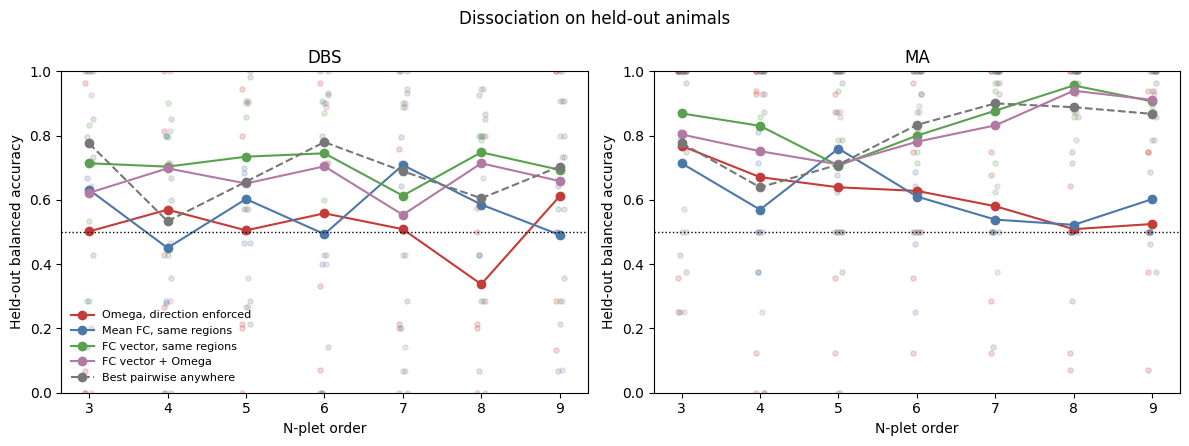

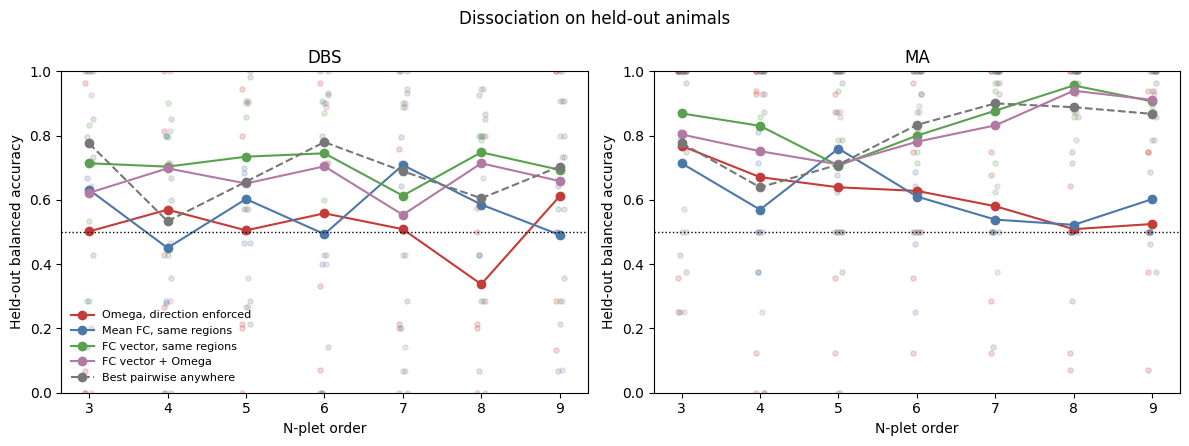

In [37]:
MODEL_LABELS = {
    'omega_direction': 'Omega direction (scalar)',
    'mean_fc_same_regions': 'Mean FC (scalar)',
    'fc_vector_same_regions': 'FC vector (n(n-1)/2 features)',
    'fc_vector_plus_omega': 'FC vector + Omega',
    'best_pairwise_anywhere': 'Best mean-FC reference',
}
MODEL_COLORS = {
    'omega_direction': 'tab:red',
    'mean_fc_same_regions': 'tab:blue',
    'fc_vector_same_regions': 'tab:green',
    'fc_vector_plus_omega': 'tab:purple',
    'best_pairwise_anywhere': '0.35',
}
PERFORMANCE_METRICS = (
    ('roc_auc', 'Pooled OOF ROC-AUC'),
    ('pr_auc', 'Pooled OOF PR-AUC (weighted prevalence 0.5)'),
)
for metric, metric_label in PERFORMANCE_METRICS:
    fig, axes = plt.subplots(
        1, len(DATASETS), figsize=(6 * len(DATASETS), 4.5),
        sharey=True, squeeze=False,
    )
    for column, dataset in enumerate(DATASETS):
        ax = axes[0, column]
        dataset_metrics = pooled_metrics.loc[pooled_metrics['dataset'] == dataset]
        for model, label in MODEL_LABELS.items():
            model_metrics = dataset_metrics.loc[
                dataset_metrics['model'] == model,
            ].sort_values('order')
            if not model_metrics.empty:
                ax.plot(
                    model_metrics['order'], model_metrics[metric],
                    color=MODEL_COLORS[model], marker='o', label=label,
                )
        ax.axhline(0.5, color='black', linestyle=':', linewidth=1, label='Chance (0.5)')
        ax.set(
            title=dataset, xlabel='N-plet order',
            xticks=sorted(dataset_metrics['order'].unique()), ylim=(-0.05, 1.05),
        )
        ax.grid(axis='y', alpha=0.25)
    axes[0, 0].set_ylabel(metric_label)
    axes[0, -1].legend(frameon=False, fontsize=8, loc='best')
    fig.suptitle(f'{metric_label} by n-plet order')
    fig.tight_layout()
    plt.show()

## P2 - Held-out synergy and matched-region values
Each fold is centered on its training non-responsive median; raw-sign checks are reported separately.

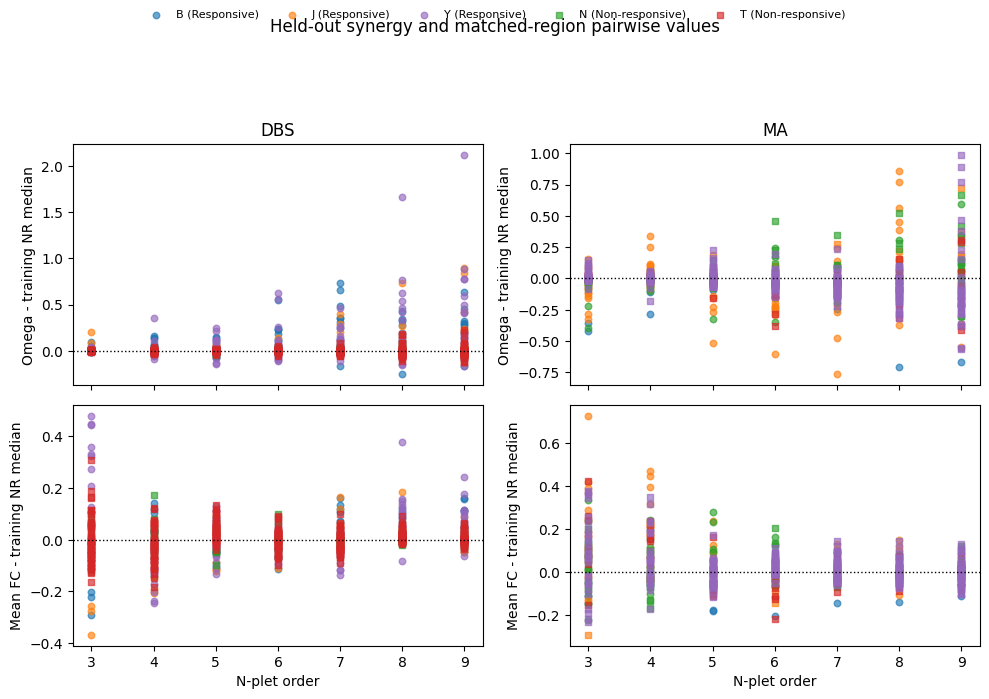

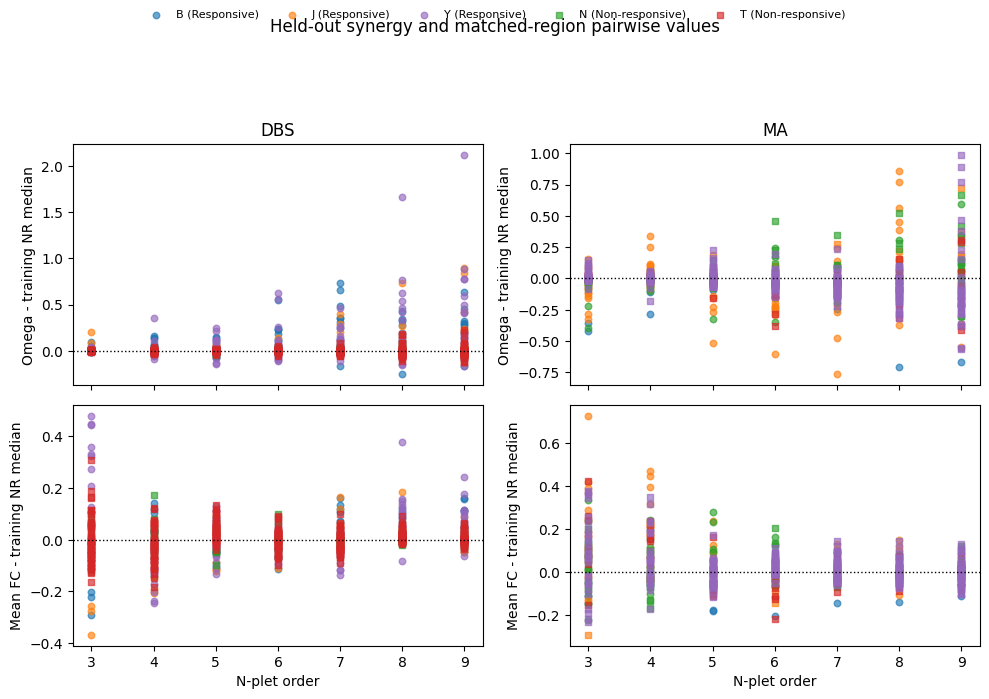

In [38]:
plot_synergy_pairwise_silence(
    pd.concat([result.predictions for result in analysis.values()], ignore_index=True),
)

## P3 - Fold-level scalar comparison
Each point is a held-out-animal ROC-AUC for one order. Only folds containing both classes are plotted; the table above retains single-class folds as non-evaluable.

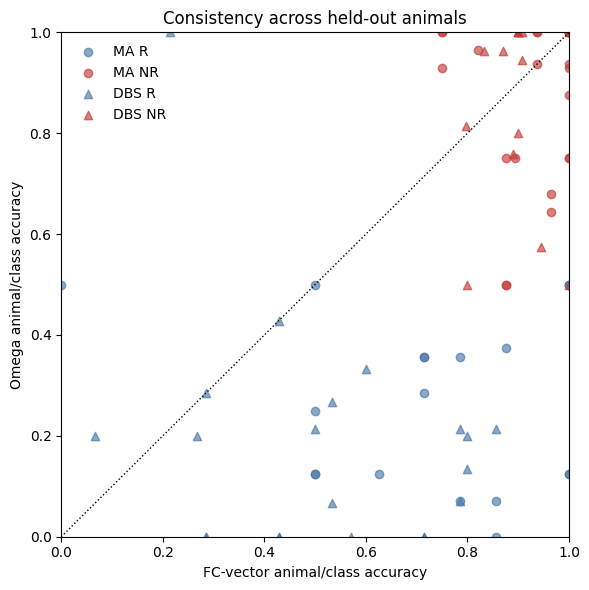

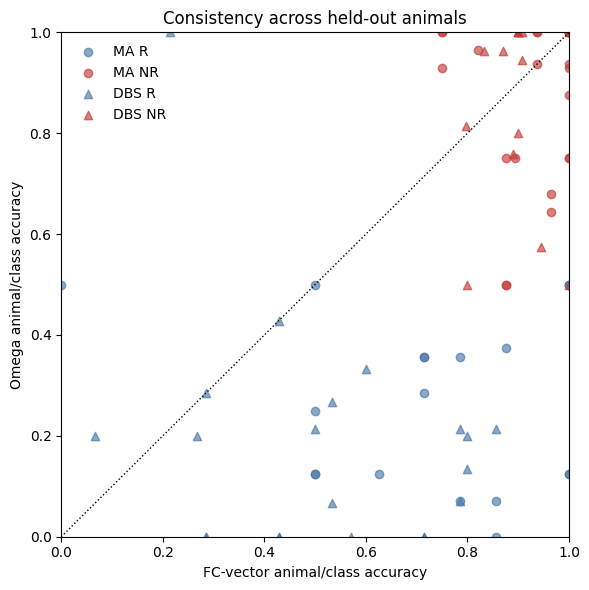

In [39]:
PRIMARY_FOLD_MODELS = {
    'omega_direction': ('Omega direction (scalar)', 'tab:red', -0.08),
    'mean_fc_same_regions': ('Mean FC (scalar)', 'tab:blue', 0.08),
}
evaluable_primary_folds = fold_metrics.loc[
    fold_metrics['model'].isin(PRIMARY_FOLD_MODELS)
    & fold_metrics['roc_auc'].notna()
]
fig, axes = plt.subplots(
    1, len(DATASETS), figsize=(6 * len(DATASETS), 4.5),
    sharey=True, squeeze=False,
)
for column, dataset in enumerate(DATASETS):
    ax = axes[0, column]
    dataset_folds = evaluable_primary_folds.loc[
        evaluable_primary_folds['dataset'] == dataset,
    ]
    for model, (label, color, offset) in PRIMARY_FOLD_MODELS.items():
        model_folds = dataset_folds.loc[dataset_folds['model'] == model]
        ax.scatter(
            model_folds['order'] + offset, model_folds['roc_auc'],
            color=color, alpha=0.75, s=28, label=label,
        )
    ax.axhline(0.5, color='black', linestyle=':', linewidth=1, label='Chance (0.5)')
    ax.set(
        title=dataset, xlabel='N-plet order',
        xticks=sorted(fold_metrics.loc[fold_metrics['dataset'] == dataset, 'order'].unique()),
        ylim=(-0.05, 1.05),
    )
    ax.grid(axis='y', alpha=0.25)
axes[0, 0].set_ylabel('Held-out-fold ROC-AUC (both classes required)')
axes[0, -1].legend(frameon=False, fontsize=8, loc='best')
fig.suptitle('Fold-specific, dimension-matched scalar ROC-AUC')
fig.tight_layout()
plt.show()